In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv")

### Preparing the dataset 

In [3]:
features = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']

### EDA

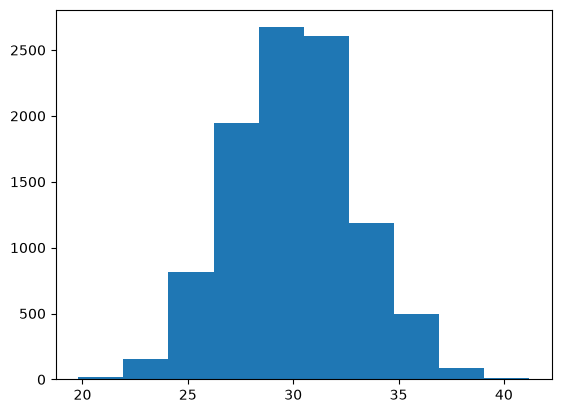

In [4]:
# `fuel_efficiency_mpg`

plt.hist(df['fuel_efficiency_mpg'])
plt.show()

### Question 1

In [7]:
# column with missing values
df[features].isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
dtype: int64

### Question 2

In [8]:
# the median (50% percentile) for variable `'horsepower'
df['horsepower'].median()

np.float64(254.0)


### Prepare and split the datas

In [27]:
# Spliting the dataset into validation (20), test (20), and training (60) sets. The split is done randomly, but with a fixed random seed for reproducibility.

n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

### Question 3

In [10]:
# Linear regression function
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]

def rmse(y, y_pred):
    se = y - y_pred
    mse = (se ** 2).mean()
    return np.sqrt(mse)

In [28]:
y_train = df_train['fuel_efficiency_mpg'].values
y_val = df_val['fuel_efficiency_mpg'].values
y_test = df_test['fuel_efficiency_mpg'].values

In [13]:
# --- OPTION 1: Fill Missing Values with 0 ---
X_train_zero = df_train[features].fillna(0).values
X_val_zero = df_val[features].fillna(0).values

# Train and predict for Option 1
w_0_zero, w_zero = train_linear_regression(X_train_zero, y_train)
y_pred_zero = w_0_zero + X_val_zero.dot(w_zero)
rmse_zero = round(rmse(y_val, y_pred_zero), 3)

In [14]:
# --- OPTION 2: Fill Missing Values with the Mean ---
# Calculate mean ONLY from the training data
train_mean = df_train['horsepower'].mean()

X_train_mean = df_train[features].fillna(train_mean).values
X_val_mean = df_val[features].fillna(train_mean).values

# Train and predict for Option 2
w_0_mean, w_mean = train_linear_regression(X_train_mean, y_train)
y_pred_mean = w_0_mean + X_val_mean.dot(w_mean)
rmse_mean = round(rmse(y_val, y_pred_mean), 3)

In [16]:
# --- Compare Results ---
print(f"RMSE when filled with 0: {rmse_zero}")
print(f"RMSE when filled with mean: {rmse_mean}")

RMSE when filled with 0: 2.205
RMSE when filled with mean: 2.202


### Question 4

In [17]:
def train_linear_regression_reg(X, y, r):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    
    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX[0, 0] -= r  # Do not regularize the bias term
    
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:] 

In [29]:
X_train_zero = df_train[features].fillna(0).values
X_val_zero = df_val[features].fillna(0).values

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w_0_zero, w_zero = train_linear_regression_reg(X_train_zero, y_train, r=r)
    y_pred_zero = w_0_zero + X_val_zero.dot(w_zero)
    rmse_zero = round(rmse(y_val, y_pred_zero), 4)
    
    print(r, "      ",rmse_zero)

0        2.2053
0.01        2.2053
0.1        2.2053
1        2.2053
5        2.2053
10        2.2053
100        2.2053


In [ ]:
# To find the best regularization parameter, we can store the RMSE values for each r in a dictionary without rounding it up and then find the r that gives the lowest RMSE.
scores = {}

for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w_0, w = train_linear_regression_reg(X_train_zero, y_train, r)
    y_pred = w_0 + X_val_zero.dot(w)
    scores[r] = rmse(y_val, y_pred)

print(scores)

best_r = min(scores, key=scores.get)
print("Best r:", best_r)
print("Best RMSE:", scores[best_r])

{0: np.float64(2.20529319475341), 0.01: np.float64(2.205293194801795), 0.1: np.float64(2.2052931952048342), 1: np.float64(2.205293199309741), 5: np.float64(2.2052932175509623), 10: np.float64(2.205293240380696), 100: np.float64(2.2052936541486763)}
Best r: 0
Best RMSE: 2.20529319475341


### Question 5

In [23]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

seed_rmse = []

for s in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    np.random.seed(s)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]
    
    y_train = df_train['fuel_efficiency_mpg'].values
    y_val = df_val['fuel_efficiency_mpg'].values

    X_train_zero = df_train[features].fillna(0).values
    X_val_zero = df_val[features].fillna(0).values

    w_0_zero, w_zero = train_linear_regression(X_train_zero, y_train)
    y_pred_zero = w_0_zero + X_val_zero.dot(w_zero)
    rmse_zero = rmse(y_val, y_pred_zero)
    seed_rmse.append(rmse_zero)
    
round(np.std(seed_rmse), 3)

np.float64(0.029)

### Question 6

In [24]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [25]:
df_combine = pd.concat([df_train, df_val])

y_combine = df_combine['fuel_efficiency_mpg'].values
y_test = df_test['fuel_efficiency_mpg'].values

In [26]:
X_combine_zero = df_combine[features].fillna(0).values
X_test_zero = df_test[features].fillna(0).values


w_0_zero, w_zero = train_linear_regression_reg(X_combine_zero, y_combine, r=0.001)
y_pred_test = w_0_zero + X_test_zero.dot(w_zero)
rmse_test = round(rmse(y_test, y_pred_test), 3)

print(rmse_test)

2.236
